# Final project: Choice 3

## Ordinary differential equations using the Runge-Kutta method

See the full project description on Canvas.

In this project you will implement the Runge-Kutta method of order 4 in order to solve an initial value problem.

Some skeleton code has been included below. The coding should be completed using Algorithm 5.2 from Burden and Faires. This book is available in the library. The details for the book are

* R L Burden, J D Faires and A M Burden. Numerical Analysis. Cengage Learning, 2016. 

  Library Shelf Mark: QA297 BURD

The book is also available as an ebook from the library. A direct link to it is given [here](http://www.vlebooks.com/vleweb/product/openreader?id=QnsBelfast&isbn=9781473737457).

# Python

526126.8173671089
525990.6190746357
136.19829247321468
Slope of log-log plot: 3.771249835187115
33
0.0016069000121206045
526138.3210496001
526138.3085238826
526020.0491077914
6.869994103908539e-05
11.50368249125313
11.49115677375812
106.76825931749772


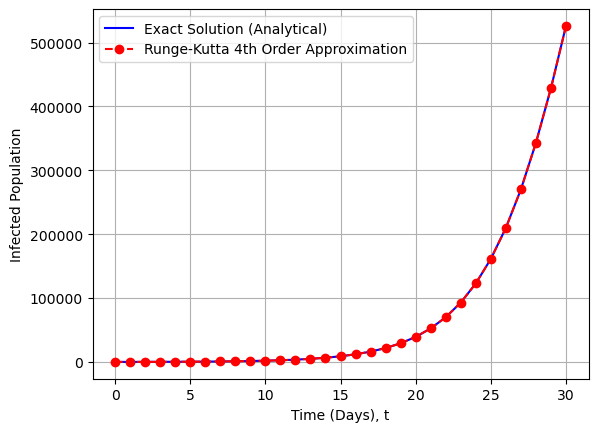

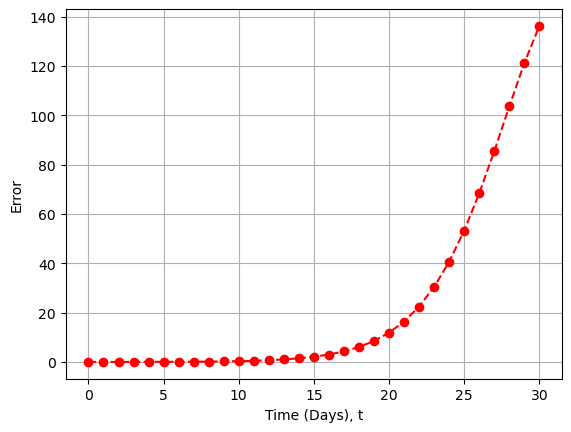

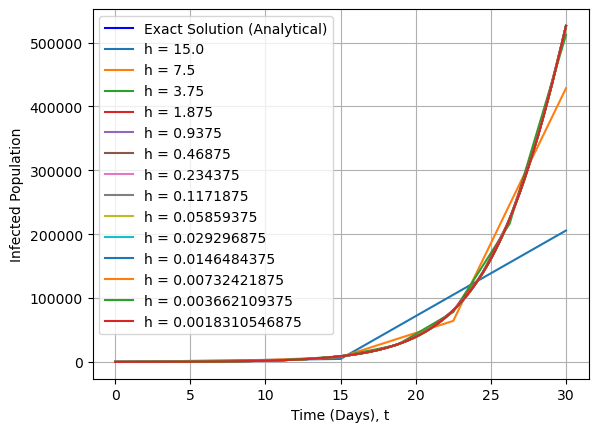

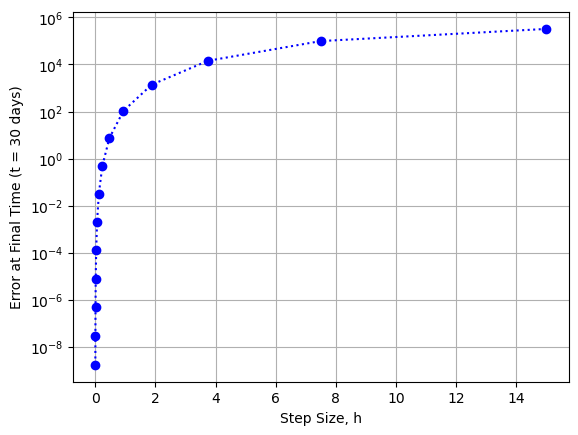

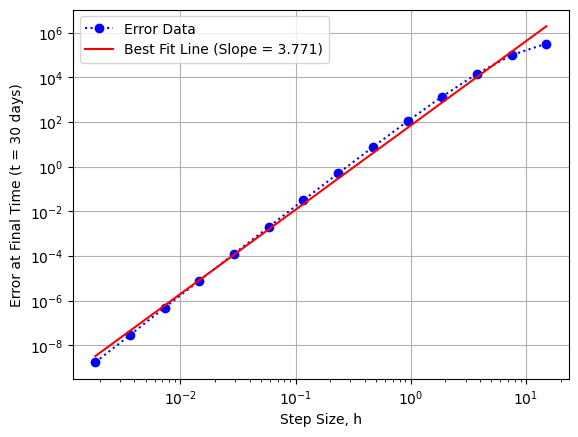

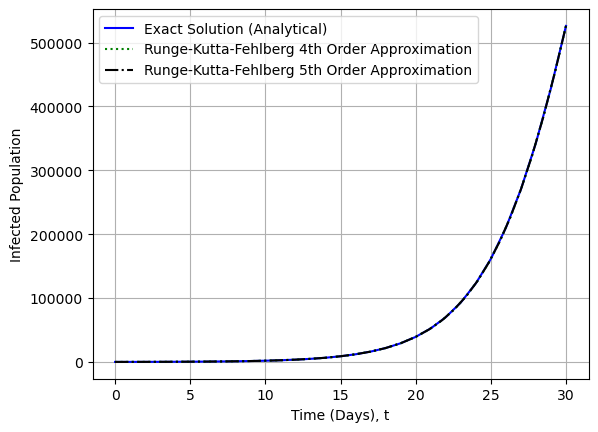

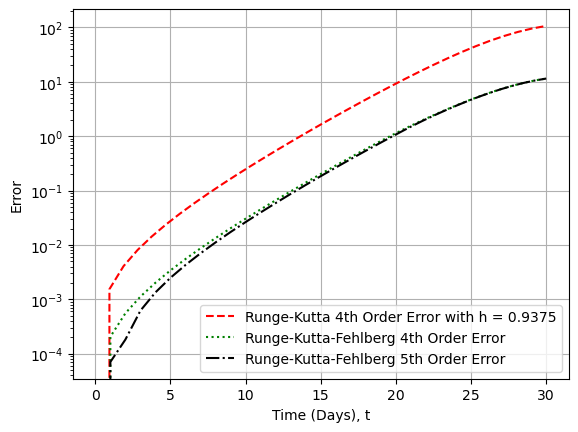

In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt
import sympy as sp
from scipy.stats import linregress
from timeit import default_timer as timer

#
# define functions
#

# Define a function, z = f(t, y), that we wish to integrate
#
# INPUTS  
#
#    (t, y): the point at which the function is evaluated
#
# OUTPUTS 
#
#    the value of the function at (t, y)

def tfunc(t, y):
	return k * (N-y) * y

#Calculates exact function using analytical solution
def exactFunc(t):
    return N/(14999 * np.exp(-N * k * t) + 1)
	
# Implementation of the Kunge-Kutta method of order 4
#
# INPUTS  
#
#   func:  the function which we will integrate, i.e. f(t, y)
#   a:     the lower endpoint of integration, i.e. t = a
#	  b:     the upper endpoint of integration, i.e. t = b
#	  n:     the number of intervals in which the 
#          range (a, b) is split
#   alpha: the initial condition, i.e. y(a) = alpha 
#
# OUTPUTS
#
#    wout: the approximation to y at the n + 1 values of tout
#    tout: the values of t at which wout is output
#

def rungekutta4(func, a, b, n, alpha):
    
    #Declaring variables
    h = (b-a) / n
    tout = [a]
    wout = [alpha]
    
    #Appling the Runge-Kutta 4 method
    for i in range(n):
        t = tout[i]
        w = wout[i]
        k1 = h * func(t, w)
        k2 = h * func(t + h / 2, w + k1 / 2)
        k3 = h * func(t + h / 2, w + k2 / 2)
        k4 = h * func(t + h, w + k3)
        wout.append(w + (k1 + 2 * k2 + 2 * k3 + k4) / 6)
        tout.append(t+h)
    
    #Returning w,t and Step Size
    return wout, tout, h

'''
#Define Variables
T, K, M = sp.symbols('T K M')

#Define Y(T)
Y = sp.Function('Y')(T)

#Calculate Derivatives
Y1 = K * (M * Y - Y**2)
Y2 = sp.diff(Y1, T).subs(sp.Derivative(Y, T), Y1)
Y3 = sp.diff(Y2, T).subs(sp.Derivative(Y, T), Y1)
Y4 = sp.diff(Y3, T).subs(sp.Derivative(Y, T), Y1)

#Simplify Derivatives
y2Simp = sp.simplify(Y2)
y3Simp = sp.simplify(Y3)
y4Simp = sp.simplify(Y4)

#Print Simplified Derivatives
print("y2(t)=", y2Simp)
print("y3(t)=", y3Simp)
print("y4(t)=", y4Simp)

def taylor_series(t, y, h, k, N):

    #Subbing Values into Derivatives
    y1 = Y1.subs({K:k,Y:y,T:t,M:N}).evalf()
    y2 = y2Simp.subs({K:k,Y:y,T:t,M:N}).evalf()
    y3 = y3Simp.subs({K:k,Y:y,T:t,M:N}).evalf()
    y4 = y4Simp.subs({K:k,Y:y,T:t,M:N}).evalf()

    #Taylor Series 4th Order
    return y + h * y1 + (h**2 / 2) * y2 + (h**3 / 6) * y3 + (h**4 / 24) * y4

'''

#Declaring variables
a = 0
b = 30
N = 1500000
n = 30
k = 2e-7
alpha = 100
mValues = [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192, 16384]
fwList = []
ftList = []
ssList = []
runtimes = []

#Calling rungekutta4 function
w, t, ss = rungekutta4(tfunc, a, b, n, alpha)

t = np.array(t)
#Getting Exact Values at each t
exact = exactFunc(t)

#Taylor Series
tVals = [alpha]

#Calulating Taylor Series 4th Order for each t 
#for i in range(len(t) - 1):
#    tVals.append(taylor_series(t[i], tVals[-1], t[i+1] - t[i], k, N))

fInfected = exact[-1]

#Print Final Number Infected for each Method
print(fInfected)
print(w[-1])
#print(tVals[-1])

#Plotting Comparison of each Method
plt.figure()
plt.plot(t,exact, 'b-', label = 'Exact Solution (Analytical)')
plt.plot(t,w, 'r--o', label = 'Runge-Kutta 4th Order Approximation')
#plt.plot(t, tVals, 'g:x', label='Taylor Series 4th Order Approximation')

#Labels and Legend
plt.xlabel('Time (Days), t')
plt.ylabel('Infected Population')
plt.grid(True)
plt.legend()

#Saving Graph
plt.savefig('graph1.png', bbox_inches='tight')

#Calulating Error for each Method
absErr = abs(exact - w)
#absErrT = abs(exact - tVals)

#Printing Error for each Method
print(absErr[-1]) 
#print(absErrT[-1])

#Plotting Error for each Method Compared to Exact
plt.figure()
plt.plot(t,absErr, 'r--o')#, label = 'Runge-Kutta 4th Order Error')
#plt.plot(t, absErrT, 'g:x', label='Taylor Series 4th Order Error')

#Labels and Legend
plt.xlabel('Time (Days), t')
plt.ylabel('Error')
plt.grid(True)
#plt.legend()

#Saving Graph
plt.savefig('graph2.png', bbox_inches='tight')

#Calculating w,t and Step Size for Increasing Number of Steps
for m in mValues:

    #Start timer
    st = timer()
    
    fw, ft, stepSize = rungekutta4(tfunc, a, b, m, alpha)

    #End timer
    et = timer()

    #Calculate run time
    rt = et-st
    
    #Adding Values to Respective List
    fwList.append(fw)
    ftList.append(ft)
    ssList.append(stepSize)
    runtimes.append(rt)

#Plotting Graph Comparing Increasing Number of Steps to Exact Function
plt.figure()
plt.plot(t,exact, 'b-', label = 'Exact Solution (Analytical)')
for i in range(len(mValues)):
    plt.plot(ftList[i], fwList[i], label = f'h = {ssList[i]}')

#Labels and Legend
plt.xlabel('Time (Days), t')
plt.ylabel('Infected Population')
plt.legend()
plt.grid(True)

#Saving Graph
plt.savefig('graph3.png', bbox_inches='tight')

#Calculating Error at 30 Days Between each Step Size and Exact Function
abs_err = []
for i in range(len(mValues)):
    aEr = abs(fwList[i][-1] - fInfected)
    abs_err.append(aEr)

#Plotting Error at 30 Days using Log Scale on y-axis
plt.figure()
plt.semilogy(ssList, abs_err, 'b:o')

#Labels and Legend
plt.xlabel('Step Size, h')
plt.ylabel('Error at Final Time (t = 30 days)')
plt.grid(True)

#Saving Graph
plt.savefig('graph4.png', bbox_inches='tight')

#Plotting Error at 30 Days using Log-Log Scale
plt.figure()
plt.loglog(ssList, abs_err, 'b:o', label='Error Data')

#Labels and Legend
plt.xlabel('Step Size, h')
plt.ylabel('Error at Final Time (t = 30 days)')
plt.grid(True)

#Calculating Log values of Step Size Values and Error
logSS = np.log10(ssList)
logErr = np.log10(abs_err)

#Linear regression to get Slope
res = linregress(logSS, logErr)
print(f"Slope of log-log plot: {res.slope}")

#Line of Best Fit
logErrFit = res.slope * logSS + res.intercept
plt.loglog(ssList, 10**logErrFit, 'r-', label=f'Best Fit Line (Slope = {res.slope:.3f})')
plt.legend()

#Saving Graph
plt.savefig('graph5.png', bbox_inches='tight')

#Write Information to File
with open('rt.csv', 'w') as f:
    
    #Define Column Headers
    headers = '"Step Size, h","Number of Steps, n","Error at t = 30 Days","Runtime(s)"\n'
    f.write(headers)  # Write headers to file
    
    #Combine the 4 Lists into Rows
    results = zip(ssList, mValues, abs_err, runtimes)
    
    #Write Each Row to the CSV
    for row in results:
        f.write(f"{row[0]},{row[1]},{row[2]:.16e},{row[3]:.16e}\n")

#Runge-Kutta-Fehlberg Method
def rkfMethod(func, a, b, alpha, tol, hmin, hmax):

    #Declaring Variables
    i = 0
    Flag = 1
    tout = [a]
    wout = [alpha]
    wout2 = [alpha]
    h = hmax
    hList = []
    step = 0
    
    while Flag == 1:

        #Increasing Step Number
        step+=1
        
        #Calculating Values
        w = wout[i]
        w2 = wout2[i]
        t = tout[i]
        k1 = h * func(t, w)
        k2 = h * func(t + h / 4, w + k1 / 4)
        k3 = h * func(t + 3 * h / 8, w + 3 * k1 / 32 + 9 * k2 / 32)
        k4 = h * func(t + 12 * h / 13, w + 1932 * k1 / 2197 - 7200 * k2 / 2197 + 7296 * k3 / 2197)
        k5 = h * func(t + h, w + 439 * k1 / 216 - 8 * k2 + 3680 * k3 / 513 - 845 * k4 / 4104)
        k6 = h * func(t + h / 2, w - 8 * k1 / 27 + 2 * k2 - 3544 * k3 / 2565 + 1859 * k4 / 4104 - 11 * k5 / 40)

        #Calculating R
        R = abs(k1 / 360 - 128 * k3 / 4275 - 2197 * k4 / 75240 + k5 / 50 + 2 * k6 / 55) / h
  
        if R <= tol:

            #Setting New Values
            t+= h

            #Adding Values to Respective List
            tout.append(t)
            wout.append(w + 25 * k1 / 216 + 1408 * k3 / 2565 + 2197 * k4 / 4104 - k5 / 5)
            wout2.append(w + 16 * k1 / 135 + 6656 * k3 / 12825 + 28561 * k4 / 56430 - 9 * k5 / 50 + 2 * k6 / 55 )
            hList.append(h)

            #Increasing Counter
            i+= 1
        
        delta = 0.84 * (tol / R)**(1/4)

        if delta <= 0.1:
            h = 0.1 * h
        elif delta >= 4:
            h = 4*h
        else:
            h = delta * h

        if h > hmax:
            h = hmax

        if t >= b:
            Flag = 0
        elif t + h > b:
            h = b - t
        elif h < hmin:
            Flag = 0
            print('Minimum h exceeded')
            print('Procedure completed unsuccessfully')

    #Returning w,t and Step Size
    return wout, wout2, tout, hList, step

#Declaring Variables
hmin = 0.5
hmax = 1
tol = 1e-1

#Start timer
st = timer()

#Calling the RKF Function
w2, w3, t2, h2, step = rkfMethod(tfunc, a, b, alpha, tol, hmin, hmax)

#Printing Number of Steps
print(step)

#End timer
et = timer()

#Calculate run time
rt = et-st

#Printing runtime
print(rt)

#Printing Final Infected
print(w2[-1])
print(w3[-1])

#Plotting Comparison of Methods
plt.figure()
plt.plot(t,exact, 'b-', label = 'Exact Solution (Analytical)')
plt.plot(t2,w2, 'g:', label = 'Runge-Kutta-Fehlberg 4th Order Approximation')
plt.plot(t2,w3, 'k-.', label = 'Runge-Kutta-Fehlberg 5th Order Approximation')

#labels and Legend
plt.xlabel('Time (Days), t')
plt.ylabel('Infected Population')
plt.grid(True)
plt.legend()

#Saving Graph
plt.savefig('graph6.png', bbox_inches='tight')

#Calculating Error between Exact and RKF
t2 = np.array(t2)
exact2 = exactFunc(t2)
absErrRKF4 = abs(exact2 - w2)
absErrRKF5 = abs(exact2 - w3)

#Tracking Position in List
pos = 0
for i,m in enumerate(mValues):
    if m == 32:
        pos = i

#Printing Final Infected
print(fwList[pos][-1])

#Printing runtime
print(runtimes[pos])

#Calculating Exact Error
exact4 = exactFunc(np.array(ftList[pos]))
aErr = abs(exact4 - fwList[pos])

#Printing Error
print(absErrRKF4[-1])
print(absErrRKF5[-1])
print(aErr[-1])

#Plotting Comparison of Errors of Methods using a Log Scale on y-axis
plt.figure()
plt.semilogy(ftList[pos], aErr, 'r--', label = f'Runge-Kutta 4th Order Error with h = {ssList[pos]}')
plt.semilogy(t2, absErrRKF4, 'g:', label = 'Runge-Kutta-Fehlberg 4th Order Error')
plt.semilogy(t2, absErrRKF5, 'k-.', label='Runge-Kutta-Fehlberg 5th Order Error')

#Labels and Legend
plt.xlabel('Time (Days), t')
plt.ylabel('Error')
plt.grid(True)
plt.legend()

#Saving Graph
plt.savefig('graph7.png', bbox_inches='tight')